# Urban Mobility Intelligence
**Jaypee Institute of Information Technology · Data Mining and Data Warehousing Lab · 26B16CS313**

**Submitted by** Ankush (2401030321), Anvi (2401030322), Ananya Aggarwal (2401030329), Utkarsh Singh (2401030339)  
**Submitted to** Dr. Diksha Pandey, Dr. Rajshree Srivastava and Dr. Sayani Ghosal

We analyze NYC Yellow Taxi trips from February through April 2024 and join pickup and drop-off taxi zones and daily NOAA Central Park weather. The notebook covers extraction, preprocessing, a dimensional warehouse and SQL OLAP, rule mining, supervised and unsupervised learning, spatial and temporal analysis, and dashboard exports.

**Run instructions.** In Jupyter install dependencies with `%pip install pandas numpy pyarrow matplotlib scikit-learn pillow pyshp`, then restart the kernel and run all cells. The first run downloads and caches the official sources in `urban_mobility_data/raw`. The warehouse and exports are regenerated on each run. Change `KEEP` to 1.0 for a census of the selected records if hardware permits. Counts in this run are retained sample counts.

**Sources** [NYC TLC trip records and zone lookup](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) · [NYC Taxi Zone polygons](https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip) · [NOAA daily summaries for Central Park](https://www.ncei.noaa.gov/data/daily-summaries/access/USW00094728.csv).

**Measurement.** Demand means completed, eligible Yellow Taxi trips in the sample. The delay label uses a distance-adjusted travel-time benchmark learned from February. TLC provides no scheduled arrival or congestion ground truth. The data cover parts of two seasons and one weather station, so seasonal and weather comparisons are descriptive, with no causal interpretation. No identifying fields are used.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import json, sqlite3, shutil, subprocess, html
from itertools import combinations
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, average_precision_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score, mean_squared_error, mean_absolute_error)
from PIL import Image, ImageFilter, ImageOps

ROOT = Path('urban_mobility_data')
RAW, OUT = ROOT/'raw', ROOT/'results'
for folder in (RAW, OUT):
    folder.mkdir(parents=True, exist_ok=True)
SEED, KEEP = 313, .05
MONTHS = ['2024-02', '2024-03', '2024-04']
base = 'https://d37ci6vzurychx.cloudfront.net'
sources = {f'yellow_tripdata_{m}.parquet': f'{base}/trip-data/yellow_tripdata_{m}.parquet' for m in MONTHS}
sources.update({
    'taxi_zone_lookup.csv': f'{base}/misc/taxi_zone_lookup.csv',
    'USW00094728.csv': 'https://www.ncei.noaa.gov/data/daily-summaries/access/USW00094728.csv',
    'taxi_zones.zip': f'{base}/misc/taxi_zones.zip',
})
for name, url in sources.items():
    dst = RAW/name
    if not dst.exists():
        temp = dst.with_suffix(dst.suffix+'.part')
        urlretrieve(url, temp)
        temp.replace(dst)
display(pd.DataFrame([(k, (RAW/k).stat().st_size) for k in sources], columns=['source','bytes']))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.sparse import csr_matrix, issparse


,source,bytes
0,yellow_tripdata_2024-02.parquet,50349284
1,yellow_tripdata_2024-03.parquet,60078280
2,yellow_tripdata_2024-04.parquet,59133625
3,taxi_zone_lookup.csv,12331
4,USW00094728.csv,17847300
5,taxi_zones.zip,1022574


## 1. Extract and clean
Project only the modeled columns from Parquet. Select a reproducible Bernoulli sample with equal probability across source files and validate pickup month against the file month. Identical projected rows are treated as duplicates. Without a TLC trip identifier this check can also remove legitimate trips whose projected values coincide. Business-rule exclusions cover impossible durations, distances, speeds and invalid monetary amounts. Plausible unusual observations remain available for anomaly detection. Passenger counts are imputed with each source month's median valid count and flagged. Missing weather observations receive an Unknown category and retain missing numeric measurements. Payment and rate codes outside the declared dictionaries map to Unknown.

In [2]:
trip_columns = {
 'tpep_pickup_datetime':'pickup', 'tpep_dropoff_datetime':'dropoff',
 'PULocationID':'pickup_id', 'DOLocationID':'dropoff_id',
 'passenger_count':'passengers', 'trip_distance':'distance_mi',
 'fare_amount':'fare', 'tip_amount':'tip', 'total_amount':'total',
 'payment_type':'payment_id','RatecodeID':'rate_id'}
zones = pd.read_csv(RAW/'taxi_zone_lookup.csv').rename(columns={
    'LocationID':'location_id','Borough':'borough','Zone':'zone'})
zones = zones[zones.location_id.between(1,263)].copy()
zones['service_zone'] = zones.service_zone.fillna('Unknown')
valid_zones = set(zones.location_id)
audit, pieces = [], []
rng = np.random.default_rng(SEED)
for month in MONTHS:
    source = pq.ParquetFile(RAW/f'yellow_tripdata_{month}.parquet')
    batches = []
    for batch in source.iter_batches(batch_size=100_000, columns=list(trip_columns)):
        part = batch.to_pandas()
        batches.append(part.loc[rng.random(len(part)) < KEEP])
    data = pd.concat(batches, ignore_index=True).rename(columns=trip_columns)
    log = {'month':month, 'raw':source.metadata.num_rows, 'sampled':len(data)}
    before = len(data)
    data = data.drop_duplicates().copy()
    log['duplicate_removed'] = before-len(data)
    data['pickup'] = pd.to_datetime(data.pickup, errors='coerce')
    data['dropoff'] = pd.to_datetime(data.dropoff, errors='coerce')
    data['duration_min'] = (data.dropoff-data.pickup).dt.total_seconds()/60
    data['speed_mph'] = 60*data.distance_mi/data.duration_min
    checks = {
        'date': data.pickup.dt.strftime('%Y-%m').eq(month) & data.dropoff.notna(),
        'zone': data.pickup_id.isin(valid_zones) & data.dropoff_id.isin(valid_zones),
        'duration_distance_speed': data.duration_min.between(1,180) &
             data.distance_mi.between(.1,100) & data.speed_mph.between(.2,85),
        'money': data.fare.gt(0) & data.total.gt(0) & data.tip.ge(0) &
             np.isfinite(data[['fare','tip','total']]).all(axis=1)
    }
    keep = pd.Series(True, index=data.index)
    for reason, valid in checks.items():
        log[reason+'_removed'] = int((keep & ~valid).sum())
        keep &= valid
    data = data.loc[keep].copy()
    valid_passengers = data.passengers.where(data.passengers.between(1,6) & data.passengers.mod(1).eq(0))
    data['passengers_imputed'] = valid_passengers.isna().astype(int)
    data['passengers'] = valid_passengers.fillna(valid_passengers.median()).astype(int)
    log['passengers_imputed'] = data.passengers_imputed.sum()
    log['retained'] = len(data)
    audit.append(log)
    pieces.append(data)
trips = pd.concat(pieces, ignore_index=True)
audit = pd.DataFrame(audit)
assert (audit.sampled == audit.retained+audit.filter(like='_removed').sum(axis=1)).all()
display(audit)

W20261122 13:39:15.084077 1968664576 cpu_info.cc:239] IOError: sysctlbyname failed for 'hw.l1dcachesize'. Detail: [errno 1] Operation not permitted
W20261122 13:39:15.084286 1968664576 cpu_info.cc:239] IOError: sysctlbyname failed for 'hw.l2cachesize'. Detail: [errno 1] Operation not permitted
W20261122 13:39:15.084409 1968664576 cpu_info.cc:239] IOError: sysctlbyname failed for 'hw.l3cachesize'. Detail: [errno 1] Operation not permitted
W20261122 13:39:15.084523 1968664576 cpu_info.cc:239] IOError: sysctlbyname failed for 'hw.optional.neon'. Detail: [errno 1] Operation not permitted


,month,raw,sampled,duplicate_removed,date_removed,zone_removed,duration_distance_speed_removed,money_removed,passengers_imputed,retained
0,2024-02,3007526,150602,0,0,1457,3985,1715,8941,143445
1,2024-03,3582628,178872,0,1,1720,5136,2554,19823,169461
2,2024-04,3514289,176170,0,1,1840,3039,2356,21747,168934


In [3]:
dates = pd.date_range('2024-02-01','2024-04-30')
noaa = pd.read_csv(RAW/'USW00094728.csv', usecols=['DATE','PRCP','SNOW','TMAX','TMIN'], parse_dates=['DATE'])
weather = noaa.set_index('DATE').reindex(dates).rename_axis('date').reset_index()
weather = weather.rename(columns={'PRCP':'precip_mm','SNOW':'snow_mm','TMAX':'tmax_tenth_c','TMIN':'tmin_tenth_c'})
weather['precip_mm'] = weather.precip_mm / 10  # GHCN PRCP is recorded in tenths of a millimeter.
weather['tmean_proxy_c'] = (weather.tmax_tenth_c+weather.tmin_tenth_c)/20
weather['weather_category'] = np.select(
    [weather.snow_mm.gt(0),weather.precip_mm.ge(10),weather.precip_mm.gt(0),
     weather.snow_mm.eq(0)&weather.precip_mm.eq(0)],
    ['Snow','Heavy precipitation','Light precipitation','Dry'], default='Unknown')
weather['weather_id'] = weather.date.dt.strftime('%Y%m%d').astype(int)
display(weather.groupby('weather_category').size().rename('days').to_frame())
display(weather[['precip_mm','snow_mm','tmean_proxy_c']].isna().sum().rename('missing_days').to_frame())

hours = pd.date_range(dates.min(), dates.max()+pd.Timedelta(hours=23), freq='h')
time = pd.DataFrame({'pickup_hour_ts':hours,'time_id':np.arange(1,len(hours)+1)})
time['date'] = time.pickup_hour_ts.dt.normalize()
time['month'] = time.date.dt.strftime('%Y-%m')
time['season'] = np.where(time.date.dt.month.eq(2),'Winter','Spring')
time['weekday'] = time.date.dt.day_name()
time['day_type'] = np.where(time.date.dt.dayofweek.ge(5),'Weekend','Weekday')
time['hour'] = time.pickup_hour_ts.dt.hour
time['period'] = np.select([time.hour.between(7,9),time.hour.between(16,19)],
                           ['Morning peak','Evening peak'], default='Off-peak')
time['rush_hour'] = (time.day_type.eq('Weekday') & time.period.ne('Off-peak')).astype(int)
trips['pickup_hour_ts'] = trips.pickup.dt.floor('h')
trips = trips.merge(time, on='pickup_hour_ts', validate='many_to_one').merge(
    weather[['date','weather_id','weather_category']], on='date', validate='many_to_one')
trips['distance_category'] = pd.cut(trips.distance_mi,[0,1,3,7,np.inf],labels=['≤1','1–3','3–7','>7'])
trips['fare_category'] = pd.cut(trips.fare,[0,10,25,50,np.inf],labels=['≤10','10–25','25–50','>50'])
distance_band = pd.cut(trips.distance_mi,[0,1,2,3,5,8,12,20,np.inf])
baseline = trips.loc[trips.month.eq(MONTHS[0])].groupby(
    distance_band, observed=True).duration_min.quantile(.85)
trips['benchmark_min'] = distance_band.map(baseline).astype(float)
assert trips.benchmark_min.notna().all()
trips['excess_min'] = (trips.duration_min-trips.benchmark_min).clip(lower=0)
trips['high_delay'] = trips.duration_min.gt(trips.benchmark_min).astype(int)
trips['delay_category'] = np.where(trips.high_delay.eq(1),'High delay','Normal')
display(baseline.rename('February duration P85 (min)').to_frame())

,days
weather_category,
Dry,56
Heavy precipitation,9
Light precipitation,23
Snow,2


,missing_days
precip_mm,0
snow_mm,0
tmean_proxy_c,0


/var/folders/zc/xk6zvjxs5vb_p0lhz27hzk100000gn/T/ipykernel_3901/980634413.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  hours = pd.date_range(dates.min(), dates.max()+pd.Timedelta(hours=23), freq='h')


,February duration P85 (min)
distance_mi,
"(0.0, 1.0]",8.983333
"(1.0, 2.0]",15.150000
"(2.0, 3.0]",21.383333
"(3.0, 5.0]",28.100000
"(5.0, 8.0]",34.216667
"(8.0, 12.0]",41.255833
"(12.0, 20.0]",61.316667
"(20.0, inf]",66.807500


## 2. Data warehouse
**Star grain** one cleaned, sampled trip in FACT_TRIP. Pickup and drop-off are role-playing location dimensions with separate foreign keys. DIM_TIME has one local wall-clock hour per row and DIM_WEATHER has one local calendar day per row. The spring clock change introduces a nominal hour that never occurred. Exposure-based summaries exclude that hour. Trip duration is computed from TLC wall-clock stamps and a ride crossing the spring change can be misstated.

**Snowflake extension** a zone references its borough, allowing a normalized geographic hierarchy. **Galaxy extension** FACT_TRIP and FACT_BOROUGH_HOUR share time and weather dimensions. The aggregate fact uses borough and hour grain, including zero sampled trips. Compare or join measures only after aggregation to compatible grains. SQLite is used so the project runs without a database server.

In [4]:
pay_labels = {0:'Unknown',1:'Credit card',2:'Cash',3:'No charge',4:'Dispute',5:'Unknown (TLC)',6:'Voided trip'}
rate_labels = {0:'Unknown',1:'Standard',2:'JFK',3:'Newark',4:'Nassau or Westchester',
               5:'Negotiated',6:'Group ride',99:'Unknown (TLC)'}
payment = pd.Series(pay_labels,name='payment').rename_axis('payment_id').reset_index()
rate = pd.Series(rate_labels,name='rate').rename_axis('rate_id').reset_index()
for field, labels in [('payment_id',pay_labels),('rate_id',rate_labels)]:
    trips[field] = trips[field].where(trips[field].isin(labels),0).astype(int)
borough = pd.DataFrame({'borough':sorted(zones.borough.unique())})
borough.insert(0,'borough_id',range(1,len(borough)+1))
borough_map = zones.set_index('location_id').borough
trips['borough'] = trips.pickup_id.map(borough_map)
usable_time = time.loc[time.pickup_hour_ts.ne(pd.Timestamp('2024-03-10 02:00'))]
hourly = (usable_time.assign(_cross=1).merge(borough.assign(_cross=1),on='_cross')
          .drop(columns='_cross').merge(weather[['date','weather_id','weather_category']],on='date'))
hourly = hourly.merge(trips.groupby(['time_id','borough']).agg(
    demand=('high_delay','size'), delayed=('high_delay','sum'),
    duration_sum=('duration_min','sum')).reset_index(),on=['time_id','borough'],how='left')
hourly[['demand','delayed','duration_sum']] = hourly[['demand','delayed','duration_sum']].fillna(0)
p75 = hourly[hourly.month.eq(MONTHS[0])].groupby('borough').demand.quantile(.75)
hourly['demand_category'] = np.select(
    [hourly.demand.eq(0),hourly.demand.gt(hourly.borough.map(p75))],
    ['Zero','High'],default='Typical')
hourly['delay_rate'] = hourly.delayed/hourly.demand.replace(0,np.nan)
trips = trips.merge(hourly[['time_id','borough','demand_category']],
                    on=['time_id','borough'],how='left',validate='many_to_one')
trips['demand_category'] = trips.demand_category.fillna('Unknown')
trips['trip_id'] = np.arange(1,len(trips)+1)
trips['trip_count'] = 1

tables = {
 'DIM_TIME':('time_id',time),
 'DIM_PICKUP_LOCATION':('pickup_id',zones.rename(columns={'location_id':'pickup_id'})),
 'DIM_DROPOFF_LOCATION':('dropoff_id',zones.rename(columns={'location_id':'dropoff_id'})),
 'DIM_WEATHER':('weather_id',weather),
 'DIM_PAYMENT':('payment_id',payment),
 'DIM_RATE':('rate_id',rate),
 'DIM_BOROUGH':('borough_id',borough),
}
trips_for_db = trips[['trip_id','time_id','pickup_id','dropoff_id','weather_id','payment_id','rate_id',
    'pickup','dropoff','trip_count','duration_min','distance_mi','fare','tip','total','passengers',
    'passengers_imputed','speed_mph','benchmark_min','excess_min','high_delay','delay_category',
    'distance_category','fare_category','demand_category']]
star_links = {key: table for table,(key,_) in tables.items() if table!='DIM_BOROUGH'}
zone_snowflake = zones.merge(borough,on='borough').drop(columns='borough')
galaxy = hourly[['time_id','borough_id','weather_id','demand','delayed','duration_sum','demand_category']]
db_path = OUT/'mobility.sqlite'
if 'db' in globals():
    db.close()
db_path.unlink(missing_ok=True)
db = sqlite3.connect(db_path)
db.execute('PRAGMA foreign_keys=ON')

def load_table(name, frame, primary, links=None):
    types = {'i':'INTEGER','u':'INTEGER','b':'INTEGER','f':'REAL'}
    fields = [f'"{col}" {types.get(dtype.kind,"TEXT")}' for col,dtype in frame.dtypes.items()]
    primary_fields = ','.join(primary)
    fields.append(f'PRIMARY KEY ({primary_fields})')
    for key, target in (links or {}).items():
        fields.append(f'FOREIGN KEY ({key}) REFERENCES {target}({key})')
    db.execute(f'CREATE TABLE {name} ({",".join(fields)})')
    frame.to_sql(name,db,if_exists='append',index=False,chunksize=5000)

for name,(key,frame) in tables.items():
    load_table(name,frame,[key])
load_table('FACT_TRIP',trips_for_db,['trip_id'],star_links)
load_table('DIM_ZONE_SNOWFLAKE',zone_snowflake,['location_id'],{'borough_id':'DIM_BOROUGH'})
load_table('FACT_BOROUGH_HOUR',galaxy,['time_id','borough_id'],
           {**{k:star_links[k] for k in ('time_id','weather_id')},'borough_id':'DIM_BOROUGH'})
db.execute('CREATE INDEX fact_time_pickup ON FACT_TRIP(time_id,pickup_id)')
db.commit()
assert not db.execute('PRAGMA foreign_key_check').fetchall()
assert db.execute('SELECT COUNT(*) FROM FACT_TRIP').fetchone()[0] == len(trips)
display(pd.read_sql_query('SELECT name FROM sqlite_master WHERE type="table" ORDER BY name',db))

,name
0,DIM_BOROUGH
1,DIM_DROPOFF_LOCATION
2,DIM_PAYMENT
3,DIM_PICKUP_LOCATION
4,DIM_RATE
5,DIM_TIME
6,DIM_WEATHER
7,DIM_ZONE_SNOWFLAKE
8,FACT_BOROUGH_HOUR
9,FACT_TRIP


In [5]:
joins = ''' FROM FACT_TRIP f JOIN DIM_TIME t USING(time_id)
 JOIN DIM_PICKUP_LOCATION p USING(pickup_id) JOIN DIM_WEATHER w USING(weather_id) '''
measures = '''COUNT(*) trips, ROUND(AVG(f.duration_min),2) duration_min,
 ROUND(AVG(f.fare),2) mean_fare, ROUND(100*AVG(f.high_delay),2) delay_pct'''
olap = {
 'Roll-up · day to month and season': f'''SELECT t.season,t.month,{measures} {joins}
     GROUP BY t.season,t.month UNION ALL SELECT t.season,'ALL', {measures} {joins}
     GROUP BY t.season ORDER BY season,month''',
 'Drill-down · Manhattan to zones and time periods': f'''SELECT p.zone,t.period,{measures}
     {joins} WHERE p.borough='Manhattan' GROUP BY p.zone,t.period ORDER BY trips DESC LIMIT 12''',
 'Slice · weekend': f'''SELECT t.hour,{measures} {joins}
     WHERE t.day_type='Weekend' GROUP BY t.hour ORDER BY t.hour''',
 'Dice · two boroughs, peak hours, precipitation': f'''SELECT p.borough,t.period,w.weather_category,{measures}
     {joins} WHERE p.borough IN ('Manhattan','Queens') AND t.rush_hour=1
     AND w.weather_category IN ('Snow','Heavy precipitation','Light precipitation')
     GROUP BY p.borough,t.period,w.weather_category ORDER BY trips DESC''',
 'Pivot · borough by day type': f'''SELECT p.borough,
     SUM(CASE WHEN t.day_type='Weekday' THEN 1 ELSE 0 END) weekday,
     SUM(CASE WHEN t.day_type='Weekend' THEN 1 ELSE 0 END) weekend {joins} GROUP BY p.borough''',
 'Snowflake · zone to borough': '''SELECT b.borough, COUNT(*) trips FROM FACT_TRIP f
     JOIN DIM_ZONE_SNOWFLAKE z ON f.pickup_id=z.location_id JOIN DIM_BOROUGH b USING(borough_id)
     GROUP BY b.borough ORDER BY trips DESC''',
 'Galaxy · trip activity by exposure hour': '''SELECT t.month,b.borough,COUNT(*) hours,
     ROUND(AVG(g.demand),2) trips_per_hour FROM FACT_BOROUGH_HOUR g
     JOIN DIM_TIME t USING(time_id) JOIN DIM_BOROUGH b USING(borough_id)
     GROUP BY t.month,b.borough ORDER BY t.month,trips_per_hour DESC'''
}
for name, sql in olap.items():
    display(HTML('<h4>'+html.escape(name)+'</h4>'))
    display(pd.read_sql_query(sql,db).head(12))

,season,month,trips,duration_min,mean_fare,delay_pct
0,Spring,2024-03,169461,16.10,18.86,16.25
1,Spring,2024-04,168934,16.39,19.10,17.60
2,Spring,ALL,338395,16.25,18.98,16.92
3,Winter,2024-02,143445,15.39,18.19,14.98
4,Winter,ALL,143445,15.39,18.19,14.98


,zone,period,trips,duration_min,mean_fare,delay_pct
0,Midtown Center,Off-peak,13803,14.87,16.57,21.50
1,Upper East Side South,Off-peak,13448,11.73,13.04,15.39
2,Upper East Side North,Off-peak,11585,12.11,13.69,13.55
3,Times Sq/Theatre District,Off-peak,10614,16.12,18.79,17.81
4,Lincoln Square East,Off-peak,10118,12.58,14.27,8.89
5,Penn Station/Madison Sq West,Off-peak,9702,16.95,17.31,32.49
6,Midtown East,Off-peak,9674,14.33,16.03,21.28
7,East Village,Off-peak,9178,13.09,15.23,8.35
8,West Village,Off-peak,8935,13.80,15.27,12.33
9,Upper West Side South,Off-peak,8581,12.17,14.22,7.28


,hour,trips,duration_min,mean_fare,delay_pct
0,0,8150,13.62,17.08,4.21
1,1,6494,12.93,15.79,3.23
2,2,4464,11.96,15.27,2.02
3,3,3045,11.69,15.70,1.25
4,4,1719,12.75,19.27,0.81
5,5,670,15.54,27.60,1.64
6,6,1074,14.88,26.99,1.30
7,7,1640,13.45,22.94,1.95
8,8,2623,12.27,19.34,1.49
9,9,4058,12.34,17.41,2.59


,borough,period,weather_category,trips,duration_min,mean_fare,delay_pct
0,Manhattan,Evening peak,Light precipitation,21951,14.54,15.19,21.79
1,Manhattan,Morning peak,Light precipitation,10277,13.79,15.55,16.50
2,Manhattan,Evening peak,Heavy precipitation,9725,15.49,15.90,28.37
3,Manhattan,Morning peak,Heavy precipitation,4380,14.02,15.65,20.00
4,Queens,Evening peak,Light precipitation,1864,39.90,54.10,18.24
5,Manhattan,Evening peak,Snow,858,10.48,13.11,1.40
6,Queens,Morning peak,Light precipitation,751,43.42,50.36,32.76
7,Queens,Evening peak,Heavy precipitation,619,42.02,53.26,25.85
8,Manhattan,Morning peak,Snow,458,10.64,12.32,5.46
9,Queens,Morning peak,Heavy precipitation,304,50.08,51.46,51.32


,borough,weekday,weekend
0,Bronx,908,388
1,Brooklyn,3631,1752
2,EWR,1,0
3,Manhattan,311120,124130
4,Queens,28950,10948
5,Staten Island,9,3


,borough,trips
0,Manhattan,435250
1,Queens,39898
2,Brooklyn,5383
3,Bronx,1296
4,Staten Island,12
5,EWR,1


,month,borough,hours,trips_per_hour
0,2024-02,Manhattan,696,187.41
1,2024-02,Queens,696,16.56
2,2024-02,Brooklyn,696,1.72
3,2024-02,Bronx,696,0.41
4,2024-02,Staten Island,696,0.00
5,2024-02,EWR,696,0.00
6,2024-03,Manhattan,743,205.55
7,2024-03,Queens,743,19.10
8,2024-03,Brooklyn,743,2.76
9,2024-03,Bronx,743,0.67


## 3. Association rules · Apriori
Each transaction is a borough-hour during March or April, including zero sample demand. Items encode borough, period, day type, observed weather, demand and the share of high-delay trips. A delayed share of at least 25% with at least ten trips is labeled elevated. Use minimum support 2% and minimum confidence 35%. Support measures joint frequency, confidence is the conditional outcome frequency, and lift measures confidence relative to the outcome's overall frequency. The output filters to demand or delay consequents. Correlated categories and low-frequency events warrant care.

In [6]:
transactions = [
    frozenset([f'borough={b}',f'period={p}',f'day={d}',f'weather={w}',f'demand={v}',
               'delay=' + ('limited data' if n<10 else 'elevated' if r>=.25 else 'typical')])
    for b,p,d,w,v,n,r in hourly.loc[hourly.month.ne(MONTHS[0]),
        ['borough','period','day_type','weather_category','demand_category','demand','delay_rate']]
        .itertuples(index=False,name=None)
]
def apriori(baskets, min_support):
    item_counts = Counter(item for basket in baskets for item in basket)
    active = {frozenset([i]): c/len(baskets) for i,c in item_counts.items() if c/len(baskets)>=min_support}
    supports = dict(active)
    width = 2
    while active:
        candidates = {a|b for a,b in combinations(active,2) if len(a|b)==width}
        candidates = {c for c in candidates if all(c-{i} in active for i in c)}
        counts = Counter(c for basket in baskets for c in map(frozenset,combinations(basket,width))
                         if c in candidates)
        active = {c:n/len(baskets) for c,n in counts.items() if n/len(baskets)>=min_support}
        supports.update(active)
        width += 1
    return supports

supports = apriori(transactions,.02)
rule_rows = []
for itemset,support in supports.items():
    for outcome in itemset:
        antecedent = itemset-{outcome}
        if antecedent and outcome.startswith(('demand=','delay=')):
            confidence = support/supports[antecedent]
            lift = confidence/supports[frozenset([outcome])]
            if confidence>=.35 and lift>1:
                rule_rows.append((' + '.join(sorted(antecedent)),outcome,support,confidence,lift))
rules = pd.DataFrame(rule_rows,columns=['antecedent','consequent','support','confidence','lift'])
rules = rules.sort_values(['lift','support'],ascending=False)
assert len(rules)
display(rules.head(15))
(OUT/'transactions.txt').write_text('\n'.join(','.join(sorted(b)) for b in transactions)+'\n', encoding='utf-8')

,antecedent,consequent,support,confidence,lift
176,borough=Manhattan + demand=High,delay=elevated,0.021987,0.360075,5.412218
493,borough=Manhattan + day=Weekend + demand=Typic...,delay=typical,0.023810,0.995238,4.443642
353,borough=Manhattan + day=Weekend + demand=Typical,delay=typical,0.033265,0.986486,4.404567
349,borough=Manhattan + day=Weekend + period=Off-peak,delay=typical,0.033493,0.963934,4.303874
374,borough=Manhattan + day=Weekend + weather=Dry,delay=typical,0.020278,0.927083,4.139337
161,borough=Manhattan + day=Weekend,delay=typical,0.044771,0.911833,4.071246
410,borough=Manhattan + demand=Typical + weather=L...,delay=typical,0.027797,0.890511,3.976045
139,borough=Manhattan + period=Evening peak,demand=High,0.022101,0.795082,3.958723
328,day=Weekday + delay=typical + period=Evening peak,demand=High,0.021531,0.794118,3.953922
517,borough=Manhattan + demand=Typical + period=Of...,delay=typical,0.020961,0.880383,3.930824


833468

## 4. Supervised learning and evaluation
The prediction point is pickup, assuming an intended drop-off zone is available. Actual distance, duration, final fares and daily observed weather are excluded from model inputs. The common inputs are pickup borough, intended destination borough, weekday, hour and route history from February. Route history supplies a median trip duration and distance for each pickup/drop-off pair, with global fallbacks for unseen pairs. March fits the models and April tests all of them on the same chronological holdout. ID3 uses information gain on discrete features, without gain ratio or pruning, with a depth limit and parent probability fallback for unseen values. CART, Gaussian Naïve Bayes, kNN and linear SVM share a train-only encoder and scaler. The same split evaluates a backpropagation-based MLP for duration regression using RMSE and MAE.

,period,rows,positive_rate
0,March train,14000,0.156643
1,April test,9000,0.176778


,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
1,CART,0.650,0.689,0.302,0.750,0.431,0.740,0.352
4,Linear SVM,0.623,0.625,0.263,0.627,0.370,0.671,0.293
2,Gaussian Naïve Bayes,0.281,0.544,0.191,0.950,0.318,0.654,0.267
3,kNN,0.826,0.545,0.537,0.110,0.183,0.753,0.373
5,ID3,0.821,0.509,0.406,0.027,0.051,0.643,0.266
0,Majority baseline,0.823,0.500,0.000,0.000,0.000,0.500,0.177


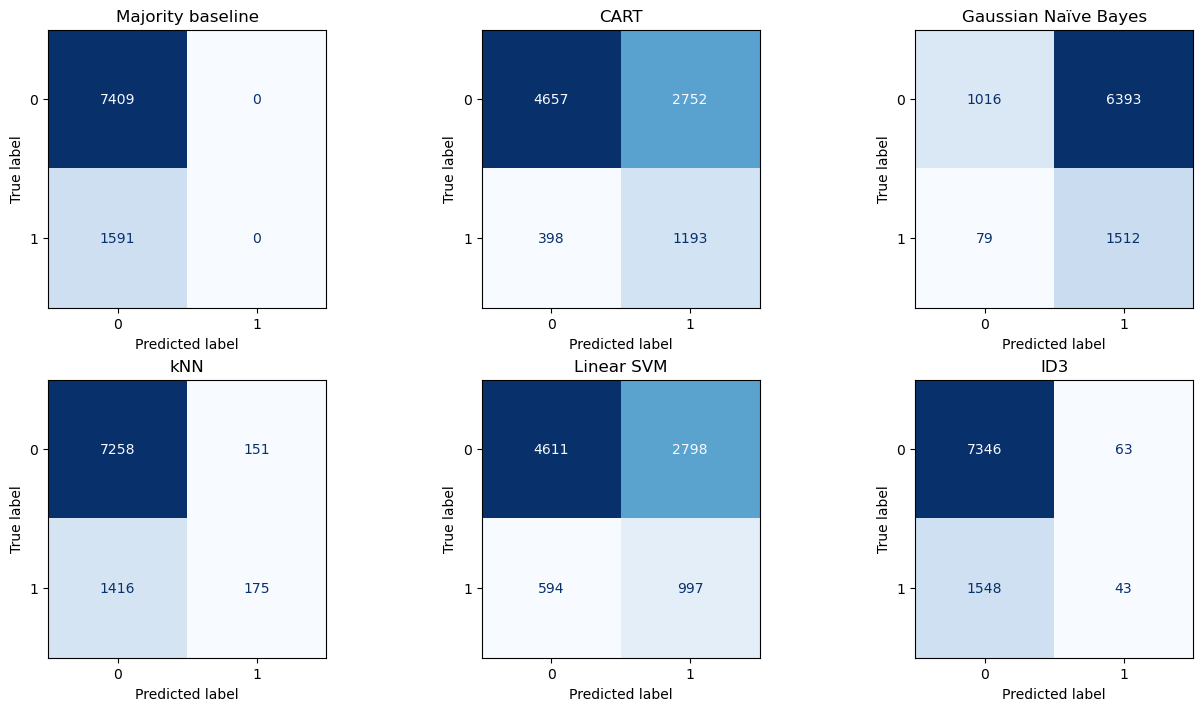

,model,rmse_min,mae_min
0,Mean baseline,13.153,9.002
1,MLP backpropagation,7.302,4.423


In [7]:
reference = trips.loc[trips.month.eq(MONTHS[0])]
historical = reference.groupby(['pickup_id','dropoff_id']).agg(
    usual_distance=('distance_mi','median'), usual_duration=('duration_min','median'))
data = trips.loc[trips.month.ne(MONTHS[0])].join(historical,on=['pickup_id','dropoff_id'])
data['destination_borough'] = data.dropoff_id.map(borough_map)
data['usual_distance'] = data.usual_distance.fillna(reference.distance_mi.median())
data['usual_duration'] = data.usual_duration.fillna(reference.duration_min.median())
fit = data[data.month.eq(MONTHS[1])].sample(n=min(14000,data.month.eq(MONTHS[1]).sum()),random_state=SEED)
test = data[data.month.eq(MONTHS[2])].sample(n=min(9000,data.month.eq(MONTHS[2]).sum()),random_state=SEED)
categorical = ['borough','destination_borough','weekday','period']
numeric = ['hour','usual_distance','usual_duration']
features = categorical+numeric
y_train, y_test = fit.high_delay, test.high_delay

def transform_features():
    return ColumnTransformer([
        ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical),
        ('numeric',StandardScaler(),numeric)])
def discrete(frame):
    return frame[categorical].assign(
        distance_band=pd.cut(frame.usual_distance,[0,1,3,7,np.inf]).astype(str),
        duration_band=pd.cut(frame.usual_duration,[0,10,20,35,np.inf]).astype(str))

def entropy(target):
    p = target.value_counts(normalize=True)
    return -(p*np.log2(p)).sum()

def id3(frame, target, depth=0):
    probability = float(target.mean())
    if not frame.shape[1] or depth==5 or target.nunique()==1 or len(target)<40:
        return probability, None, {}
    gains = {}
    for field in frame:
        groups = frame.groupby(field).groups
        gains[field] = entropy(target)-sum(
            len(index)/len(target)*entropy(target.loc[index]) for index in groups.values())
    choice = max(gains,key=gains.get)
    if gains[choice]<=1e-12:
        return probability, None, {}
    children = {value:id3(frame.loc[index].drop(columns=choice),target.loc[index],depth+1)
                for value,index in frame.groupby(choice).groups.items()}
    return probability, choice, children

def id3_score(row, node):
    probability, field, children = node
    return id3_score(row,children[row[field]]) if field and row[field] in children else probability

def assess(name, prediction, score):
    return [name,accuracy_score(y_test,prediction),balanced_accuracy_score(y_test,prediction),
            precision_score(y_test,prediction,zero_division=0),recall_score(y_test,prediction),
            f1_score(y_test,prediction),roc_auc_score(y_test,score),average_precision_score(y_test,score)]

algorithms = {
    'Majority baseline':DummyClassifier(strategy='most_frequent'),
    'CART':DecisionTreeClassifier(max_depth=9,min_samples_leaf=25,class_weight='balanced',random_state=SEED),
    'Gaussian Naïve Bayes':GaussianNB(),
    'kNN':KNeighborsClassifier(n_neighbors=25),
    'Linear SVM':LinearSVC(class_weight='balanced',random_state=SEED),
}
metrics, predictions = [], {}
for name, algorithm in algorithms.items():
    model = make_pipeline(transform_features(),algorithm).fit(fit[features],y_train)
    prediction = model.predict(test[features])
    score = model.decision_function(test[features]) if name=='Linear SVM' else model.predict_proba(test[features])[:,1]
    metrics.append(assess(name,prediction,score))
    predictions[name] = prediction
tree = id3(discrete(fit),y_train)
score = discrete(test).apply(lambda row:id3_score(row,tree),axis=1)
predictions['ID3'] = (score>=.5).astype(int)
metrics.append(assess('ID3',predictions['ID3'],score))
metrics = pd.DataFrame(metrics,columns=['model','accuracy','balanced_accuracy','precision','recall','f1','roc_auc','average_precision'])
metrics = metrics.sort_values('f1',ascending=False)
display(pd.DataFrame({'period':['March train','April test'],'rows':[len(fit),len(test)],
                      'positive_rate':[y_train.mean(),y_test.mean()]}))
display(metrics.round(3))
fig, axes = plt.subplots(2,3,figsize=(13,7),layout='constrained')
for (name,prediction),ax in zip(predictions.items(),axes.flat):
    ConfusionMatrixDisplay.from_predictions(y_test,prediction,ax=ax,colorbar=False,cmap='Blues')
    ax.set_title(name)
plt.show()

regression = []
for name, reg in [('Mean baseline',DummyRegressor()),
                  ('MLP backpropagation',MLPRegressor(hidden_layer_sizes=(32,16),max_iter=250,
                                     early_stopping=True,random_state=SEED))]:
    reg_model = make_pipeline(transform_features(),reg).fit(fit[features],fit.duration_min)
    estimate = reg_model.predict(test[features])
    regression.append((name,mean_squared_error(test.duration_min,estimate)**.5,
                       mean_absolute_error(test.duration_min,estimate)))
regression = pd.DataFrame(regression,columns=['model','rmse_min','mae_min'])
display(regression.round(3))

## 5. Zone clustering and anomaly detection
Zone profiles use pickup volume, mean duration, mean distance, proxy delay rate, weekend share and peak-hour share. Log-transform volume, standardize the inputs, and compare k from 2 through 6 by silhouette on zones with at least 100 pickups. Cluster labels are nominal. Trip anomalies use a 1.5 IQR rule and Isolation Forest on log-transformed duration, distance, fare and speed. The Isolation Forest fits on February and scores all three months. The 1% contamination is a modeling choice. Anomaly flags are signals for review and have no verified anomaly labels.

In [8]:
def zone_summary(field):
    return trips.groupby(field).agg(
        trips=('trip_count','sum'),duration_min=('duration_min','mean'),
        distance_mi=('distance_mi','mean'),delay_rate=('high_delay','mean'),
        weekend_share=('day_type',lambda values:values.eq('Weekend').mean()),
        rush_share=('rush_hour','mean')).rename_axis('location_id')
pickup_stats = zones.merge(zone_summary('pickup_id'),on='location_id',how='left')
pickup_stats['trips'] = pickup_stats.trips.fillna(0).astype(int)
pickup_stats = pickup_stats.merge(trips.groupby('dropoff_id').size().rename('dropoffs'),
    left_on='location_id',right_index=True,how='left')
pickup_stats['dropoffs'] = pickup_stats.dropoffs.fillna(0).astype(int)
profile = pickup_stats[pickup_stats.trips.ge(100)].copy()
cluster_cols = ['trips','duration_min','distance_mi','delay_rate','weekend_share','rush_share']
matrix = profile[cluster_cols].assign(trips=np.log1p(profile.trips))
scaled = StandardScaler().fit_transform(matrix)
clustering = {}
for k in range(2,7):
    labels = KMeans(n_clusters=k,n_init=20,random_state=SEED).fit_predict(scaled)
    clustering[k] = (silhouette_score(scaled,labels),labels)
chosen_k = max(clustering,key=lambda k:clustering[k][0])
profile['cluster'] = clustering[chosen_k][1]+1
display(pd.Series({k:v[0] for k,v in clustering.items()},name='silhouette').to_frame())
display(profile.groupby('cluster')[cluster_cols].mean().round(3))
pickup_stats = pickup_stats.merge(profile[['location_id','cluster']],on='location_id',how='left')

anomaly_features = ['duration_min','distance_mi','fare','speed_mph']
q1,q3 = [reference[anomaly_features].quantile(q) for q in (.25,.75)]
iqr = q3-q1
flags = trips[anomaly_features].lt(q1-1.5*iqr) | trips[anomaly_features].gt(q3+1.5*iqr)
trips['iqr_anomaly'] = flags.any(axis=1)
forest = IsolationForest(contamination=.01,random_state=SEED,n_jobs=2).fit(
    np.log1p(reference[anomaly_features].sample(n=min(20000,len(reference)),random_state=SEED)))
trips['isolation_score'] = -forest.decision_function(np.log1p(trips[anomaly_features]))
trips['isolation_anomaly'] = trips.isolation_score.gt(0)
anomalies = trips.loc[trips.iqr_anomaly | trips.isolation_anomaly,
    ['trip_id','pickup','pickup_id','dropoff_id','duration_min','distance_mi','fare',
     'speed_mph','iqr_anomaly','isolation_anomaly','isolation_score']].sort_values('isolation_score',ascending=False)
display(pd.crosstab(trips.iqr_anomaly,trips.isolation_anomaly))
display(anomalies.head(12))

,silhouette
2,0.451406
3,0.386551
4,0.415447
5,0.421182
6,0.418965


,trips,duration_min,distance_mi,delay_rate,weekend_share,rush_share
cluster,,,,,,
1,5742.696,16.898,3.395,0.152,0.335,0.273
2,1396.529,35.883,7.576,0.424,0.258,0.319


isolation_anomaly,False,True
iqr_anomaly,,
False,404543,1453
True,72030,3814


,trip_id,pickup,pickup_id,dropoff_id,duration_min,distance_mi,fare,speed_mph,iqr_anomaly,isolation_anomaly,isolation_score
18113,18114,2024-02-04 16:19:20,163,230,86.983333,0.34,85.55,0.234528,True,True,0.109566
73116,73117,2024-02-16 14:05:16,227,177,103.516667,0.70,51.50,0.405732,True,True,0.089738
243039,243040,2024-03-21 06:01:22,219,88,75.183333,0.50,70.50,0.399025,True,True,0.089563
344969,344970,2024-04-07 09:09:45,29,100,63.366667,0.30,49.50,0.284061,True,True,0.087965
279330,279331,2024-03-28 17:34:00,125,50,117.733333,4.94,87.00,2.517554,True,True,0.085951
406012,406013,2024-04-19 15:18:33,129,129,115.283333,6.42,88.40,3.341333,True,True,0.083797
155106,155107,2024-03-03 11:58:52,132,132,1.916667,0.10,85.96,3.130435,True,True,0.082501
396438,396439,2024-04-17 19:31:49,68,113,107.283333,6.69,84.20,3.741494,True,True,0.081853
89668,89669,2024-02-20 13:32:44,75,74,72.583333,47.72,177.30,39.447072,True,True,0.081006
348803,348804,2024-04-08 08:56:31,7,227,54.933333,0.20,46.50,0.218447,True,True,0.080940


## 6. Spatial, temporal and weather analysis
Zone maps use official TLC polygons in their source projected coordinates. Uncolored delay zones fall below the 100-pickup reliability threshold. A zone's delay share also reflects its trip mix and the project's benchmark. The origin–destination table summarizes zone-to-zone flows. Exposure-adjusted time and weather metrics include zero sampled pickup hours. Demand spikes use a median and scaled median absolute deviation for the same time of week across the period. Treat spike scores as exploratory because the full analysis window contributes to the baseline.

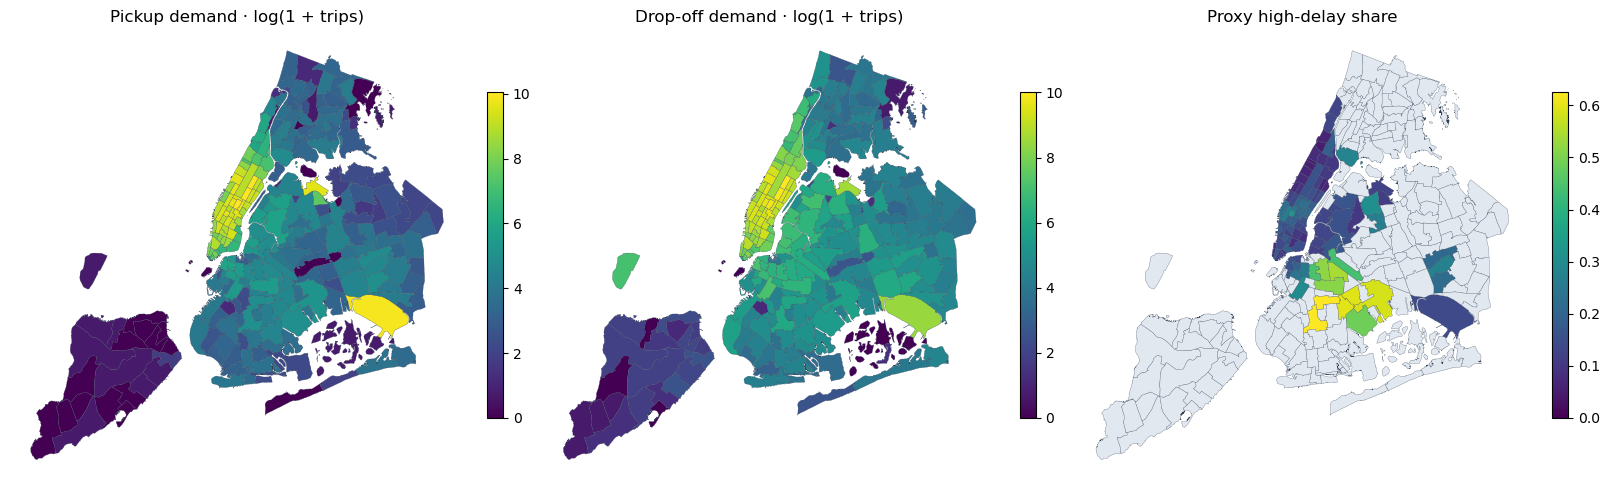

,pickup_id,dropoff_id,trips,origin,destination
12310,237,236,3404,Upper East Side South,Upper East Side North
12166,236,237,2840,Upper East Side North,Upper East Side South
12165,236,236,2198,Upper East Side North,Upper East Side North
12311,237,237,2165,Upper East Side South,Upper East Side South
8326,161,237,1584,Midtown Center,Upper East Side South
8325,161,236,1392,Midtown Center,Upper East Side North
7168,142,239,1368,Lincoln Square East,Upper West Side South
12524,239,142,1365,Upper West Side South,Lincoln Square East
12567,239,238,1276,Upper West Side South,Upper West Side North
12267,237,161,1241,Upper East Side South,Midtown Center


,zone,borough,trips,dropoffs,duration_min,delay_rate
160,Midtown Center,Manhattan,22983,17809,14.838101,0.229474
236,Upper East Side South,Manhattan,22531,20313,11.705177,0.153300
235,Upper East Side North,Manhattan,20895,22065,12.000132,0.118306
131,JFK Airport,Queens,19866,4670,42.043229,0.140944
161,Midtown East,Manhattan,17006,13733,14.299889,0.224744
229,Times Sq/Theatre District,Manhattan,16346,15131,16.285957,0.206778
141,Lincoln Square East,Manhattan,16027,13713,12.392109,0.094840
185,Penn Station/Madison Sq West,Manhattan,15781,10552,16.523069,0.330461


,zone,borough,trips
4,Arden Heights,Staten Island,0
26,Breezy Point/Fort Tilden/Riis Beach,Queens,0
43,Charleston/Tottenville,Staten Island,0
58,Crotona Park,Bronx,0
95,Forest Park/Highland Park,Queens,0
98,Freshkills Park,Staten Island,0
102,Governor's Island/Ellis Island/Liberty Island,Manhattan,0
103,Governor's Island/Ellis Island/Liberty Island,Manhattan,0


,zone,borough,trips,duration_min,delay_rate
131,JFK Airport,Queens,19866,42.043229,0.140944
34,Brownsville,Brooklyn,106,41.541352,0.594340
75,East New York,Brooklyn,183,40.787341,0.584699
88,Flatbush/Ditmas Park,Brooklyn,143,40.346154,0.622378
187,Prospect-Lefferts Gardens,Brooklyn,136,39.144363,0.625000
9,Baisley Park,Queens,147,38.439342,0.217687
38,Canarsie,Brooklyn,144,38.138889,0.486111
224,Stuyvesant Heights,Brooklyn,118,37.613136,0.542373


,zone,borough,trips,duration_min,delay_rate
187,Prospect-Lefferts Gardens,Brooklyn,136,39.144363,0.625000
88,Flatbush/Ditmas Park,Brooklyn,143,40.346154,0.622378
71,East Flatbush/Remsen Village,Brooklyn,102,37.473856,0.598039
34,Brownsville,Brooklyn,106,41.541352,0.594340
75,East New York,Brooklyn,183,40.787341,0.584699
224,Stuyvesant Heights,Brooklyn,118,37.613136,0.542373
16,Bedford,Brooklyn,108,32.700154,0.518519
60,Crown Heights North,Brooklyn,236,33.738418,0.512712


In [9]:
import shapefile
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize
import zipfile

shapes_dir = ROOT/'shapes'
shapes_dir.mkdir(exist_ok=True)
with zipfile.ZipFile(RAW/'taxi_zones.zip') as archive:
    for name in archive.namelist():
        file = Path(name)
        if file.name in {'taxi_zones.shp','taxi_zones.shx','taxi_zones.dbf'}:
            (shapes_dir/file.name).write_bytes(archive.read(name))
shape_reader = shapefile.Reader(str(shapes_dir/'taxi_zones.shp'),encoding='latin1')
polygons = []
for feature in shape_reader.iterShapeRecords():
    zone_id = int(feature.record.as_dict()['LocationID'])
    for a,b in zip(feature.shape.parts,list(feature.shape.parts)[1:]+[len(feature.shape.points)]):
        polygons.append((zone_id,feature.shape.points[a:b]))
indexed = pickup_stats.set_index('location_id')
fig, axes = plt.subplots(1,3,figsize=(16,6),layout='constrained')
for ax, field, title in zip(axes,['trips','dropoffs','delay_rate'],
        ['Pickup demand · log(1 + trips)','Drop-off demand · log(1 + trips)','Proxy high-delay share']):
    values = indexed[field].copy()
    if field=='delay_rate':
        values = values.where(indexed.trips.ge(100))
    else:
        values = np.log1p(values)
    pal = plt.get_cmap('viridis').with_extremes(bad='#e2e8f0')
    collection = PolyCollection([p for _,p in polygons],cmap=pal,
        edgecolor='#334155',linewidth=.18,norm=Normalize(vmin=0,vmax=values.max()))
    collection.set_array(np.array([values.get(key,np.nan) for key,_ in polygons]))
    ax.add_collection(collection)
    ax.autoscale()
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title)
    fig.colorbar(collection,ax=ax,shrink=.55)
plt.show()

zone_names = zones.set_index('location_id').zone
flows = trips.groupby(['pickup_id','dropoff_id']).size().rename('trips').reset_index()
flows['origin'] = flows.pickup_id.map(zone_names)
flows['destination'] = flows.dropoff_id.map(zone_names)
flows = flows.sort_values('trips',ascending=False)
display(flows.head(12))
display(pickup_stats.nlargest(8,'trips')[['zone','borough','trips','dropoffs','duration_min','delay_rate']])
display(pickup_stats.nsmallest(8,'trips')[['zone','borough','trips']])
eligible_zones = pickup_stats[pickup_stats.trips.ge(100)]
display(eligible_zones.nlargest(8,'duration_min')[['zone','borough','trips','duration_min','delay_rate']])
display(eligible_zones.nlargest(8,'delay_rate')[['zone','borough','trips','duration_min','delay_rate']])

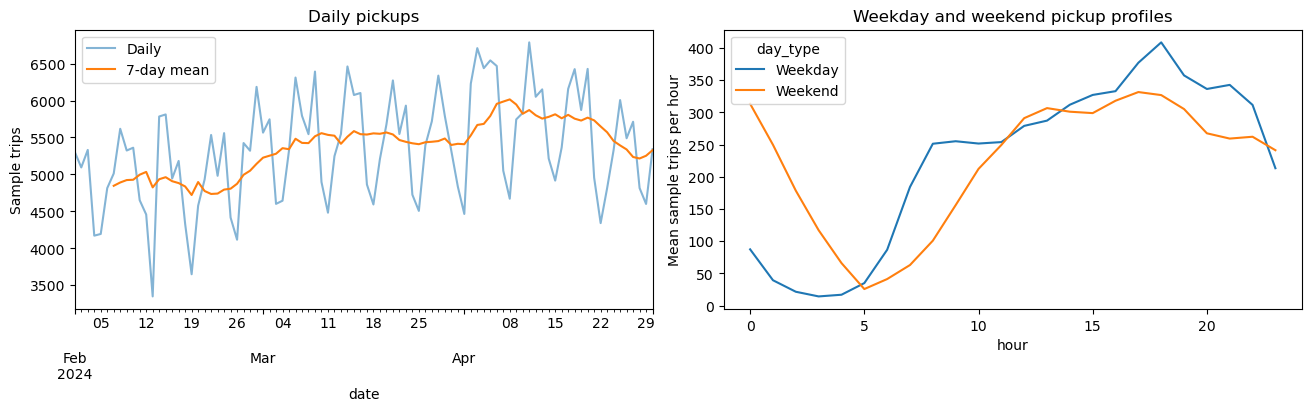

,hours,trips,delayed,trips_per_hour,mean_min,delay_pct
weather_category,,,,,,
Dry,1344,292735.0,45015.0,217.81,15.91,15.38
Heavy precipitation,216,54405.0,11772.0,251.88,16.40,21.64
Light precipitation,551,126167.0,21298.0,228.98,16.18,16.88
Snow,48,8533.0,661.0,177.77,13.29,7.75


hours     trips  delayed  trips_per_hour  mean_min  delay_pct
season month                                                                 
Spring 2024-03    743  169461.0  27530.0          228.08     16.10      16.25
       2024-04    720  168934.0  29732.0          234.63     16.39      17.60
Winter 2024-02    696  143445.0  21484.0          206.10     15.39      14.98

,hours,trips,delayed,trips_per_hour,mean_min,delay_pct
weekday,,,,,,
Thursday,312,78973.0,17115.0,253.12,17.01,21.67
Saturday,312,75685.0,10962.0,242.58,14.99,14.48
Wednesday,288,68334.0,14540.0,237.27,16.51,21.28
Friday,312,72826.0,12031.0,233.42,16.27,16.52
Tuesday,312,66839.0,12835.0,214.23,16.13,19.20
Sunday,311,61536.0,4668.0,197.86,15.03,7.59
Monday,312,57647.0,6595.0,184.77,15.80,11.44


,pickup_hour_ts,weather_category,demand,robust_z
1467,2024-04-02 04:00:00,Heavy precipitation,26.0,10.117361
257,2024-02-11 17:00:00,Dry,365.0,9.250159
642,2024-02-27 18:00:00,Heavy precipitation,528.0,8.150097
263,2024-02-11 23:00:00,Dry,299.0,7.194568
432,2024-02-19 00:00:00,Dry,100.0,7.082153
1481,2024-04-02 18:00:00,Heavy precipitation,506.0,6.913530
1513,2024-04-04 02:00:00,Light precipitation,40.0,6.407662
1791,2024-04-15 16:00:00,Dry,369.0,6.295247
761,2024-03-03 17:00:00,Dry,328.0,5.684994
434,2024-02-19 02:00:00,Dry,40.0,5.620756


In [10]:
city = hourly.groupby(['pickup_hour_ts','date','hour','weekday','day_type','month','season',
                       'weather_category'],as_index=False)[['demand','delayed','duration_sum']].sum()
same_slot = city.groupby(['weekday','hour']).demand
slot_median = same_slot.transform('median')
slot_mad = same_slot.transform(lambda v:(v-v.median()).abs().median())
city['robust_z'] = (city.demand-slot_median)/(1.4826*slot_mad.replace(0,np.nan))
city['demand_spike'] = city.robust_z.ge(3.5)
city['demand_dip'] = city.robust_z.le(-3.5)
daily = city.groupby('date').demand.sum()
hour_profiles = city.groupby(['hour','day_type']).demand.mean().unstack()
fig,axes = plt.subplots(1,2,figsize=(13,4),layout='constrained')
daily.plot(ax=axes[0],alpha=.55,label='Daily')
daily.rolling(7).mean().plot(ax=axes[0],label='7-day mean')
axes[0].set(ylabel='Sample trips',title='Daily pickups')
axes[0].legend()
hour_profiles.plot(ax=axes[1],title='Weekday and weekend pickup profiles')
axes[1].set(ylabel='Mean sample trips per hour')
plt.show()

def exposures(keys):
    summary = city.groupby(keys).agg(hours=('demand','size'),trips=('demand','sum'),
                                  delayed=('delayed','sum'),duration_sum=('duration_sum','sum'))
    return summary.assign(trips_per_hour=summary.trips/summary.hours,
                          mean_min=summary.duration_sum/summary.trips,
                          delay_pct=100*summary.delayed/summary.trips).drop(columns='duration_sum')
weather_stats = exposures(['weather_category'])
display(weather_stats.round(2))
display(exposures(['season','month']).round(2))
display(exposures(['weekday']).sort_values('trips_per_hour',ascending=False).round(2))
display(city.loc[city.demand_spike | city.demand_dip,
    ['pickup_hour_ts','weather_category','demand','robust_z']].sort_values('robust_z',ascending=False).head(15))

## 7. Syllabus extensions · text, images, WEKA and R

**Text mining** uses official taxi zone names as short documents. Normalize punctuation and case, remove stop words, and compute unigram and bigram TF-IDF features. The chart explores frequent words in the zone names. Text features can support search or exploratory grouping.

**Image preprocessing** rasterizes the real demand map, adds seeded impulse noise to create a known degradation, then median-filters and contrast-enhances it. For a user-supplied image, assign its path to `IMAGE_OVERRIDE`. Arrays are resized and normalized to [0, 1] for downstream image mining, with pixel RMSE measured on the controlled experiment. Contrast enhancement is visual and can change intensity values.

**WEKA** exports separate ARFF files, uses WEKA's Instances and InfoGainAttributeEval to inspect and validate the training data, runs five-fold cross-validation on March, then tests J48 on April. J48 is WEKA's C4.5 implementation. The Python section implements ID3 separately. Java is required. Set `RUN_WEKA=False` to export ARFF without running Java.

**R** implements Apriori and rule scoring using base R on the same transactions, with the same thresholds as the Python implementation. When Rscript is on PATH, the notebook compares the rule counts. The R script runs independently with the transaction file.

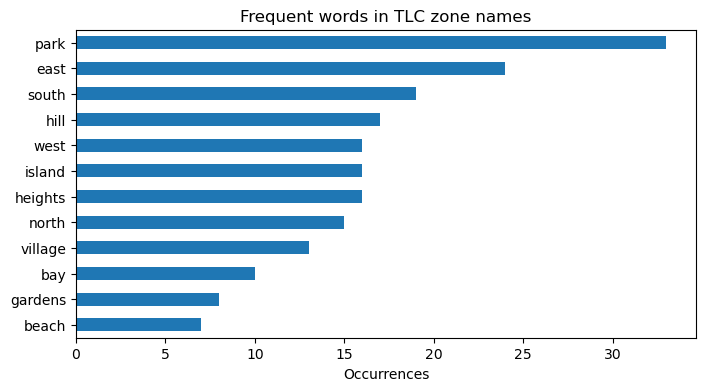

,source,normalized
0,Newark Airport,newark airport
1,Jamaica Bay,jamaica bay
2,Allerton/Pelham Gardens,allerton pelham gardens
3,Alphabet City,alphabet city
4,Arden Heights,arden heights
5,Arrochar/Fort Wadsworth,arrochar fort wadsworth
6,Astoria,astoria
7,Astoria Park,astoria park
8,Auburndale,auburndale
9,Baisley Park,baisley park


Pixel RMSE before 47.08 and after median filtering 8.76


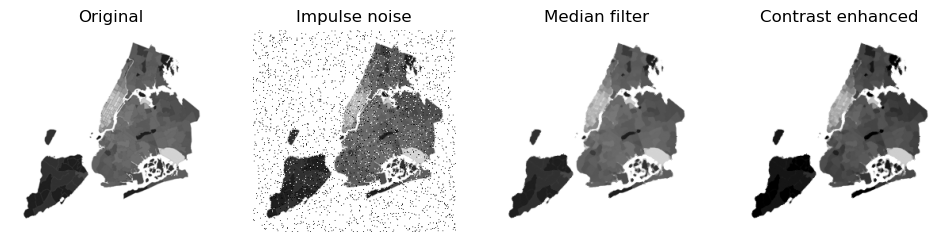

In [11]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
documents = zones.zone.fillna('').str.lower().str.replace(r'[^a-z0-9 ]',' ',regex=True)
counts = CountVectorizer(stop_words='english')
text_count = counts.fit_transform(documents)
tfidf = TfidfVectorizer(stop_words='english',ngram_range=(1,2))
text_matrix = tfidf.fit_transform(documents)
assert text_matrix.shape[0] == len(zones)
frequent = pd.Series(np.asarray(text_count.sum(axis=0)).ravel(),index=counts.get_feature_names_out()).nlargest(12)
frequent.sort_values().plot.barh(title='Frequent words in TLC zone names',figsize=(8,4))
plt.xlabel('Occurrences')
plt.show()
display(pd.DataFrame({'source':zones.zone,'normalized':documents}).head(10))

map_fig,map_ax = plt.subplots(figsize=(5,5),dpi=120)
map_collection = PolyCollection([p for _,p in polygons],cmap='viridis',edgecolor='#263548',linewidth=.15)
map_collection.set_array(np.array([np.log1p(indexed.trips.get(key,0)) for key,_ in polygons]))
map_ax.add_collection(map_collection)
map_ax.autoscale()
map_ax.set_aspect('equal')
map_ax.axis('off')
image_path = OUT/'zone_source.png'
map_fig.savefig(image_path,bbox_inches='tight',facecolor='white')
plt.close(map_fig)
IMAGE_OVERRIDE = None
original = Image.open(IMAGE_OVERRIDE or image_path).convert('L').resize((256,256))
pixels = np.array(original)
image_rng = np.random.default_rng(SEED)
noise = image_rng.random(pixels.shape)
corrupted = Image.fromarray(np.where(noise<.04,0,np.where(noise>.96,255,pixels)).astype('uint8'))
denoised = corrupted.filter(ImageFilter.MedianFilter(3))
enhanced = ImageOps.autocontrast(denoised,cutoff=1)
prepared_image = np.asarray(enhanced,dtype=np.float32)[None,...,None]/255
np.save(OUT/'prepared_image.npy',prepared_image)
def pixel_rmse(image):
    return np.sqrt(np.mean((np.asarray(image,dtype=float)-pixels)**2))
print(f'Pixel RMSE before {pixel_rmse(corrupted):.2f} and after median filtering {pixel_rmse(denoised):.2f}')
fig,axes = plt.subplots(1,4,figsize=(12,4))
for axis,image,title in zip(axes,[original,corrupted,denoised,enhanced],
                            ['Original','Impulse noise','Median filter','Contrast enhanced']):
    axis.imshow(image,cmap='gray',vmin=0,vmax=255)
    axis.set_title(title)
    axis.axis('off')
plt.show()

In [12]:
def arff_token(value):
    return "'" + str(value).replace(chr(92),chr(92)*2).replace("'",chr(92)+"'") + "'"

weka_nominals = {name:sorted(set(fit[name])|set(test[name])) for name in categorical}
def write_arff(frame,path):
    header = '\n'.join(['@RELATION yellow_taxi_delay','']+
        [f'@ATTRIBUTE {col} {{{",".join(map(arff_token,weka_nominals[col]))}}}' for col in categorical]+
        [f'@ATTRIBUTE {col} NUMERIC' for col in numeric]+
        ['@ATTRIBUTE high_delay {0,1}','','@DATA'])
    rows = (','.join([*(arff_token(v) for v in row[:len(categorical)]),
                     *(str(v) for v in row[len(categorical):])])
            for row in frame[features+['high_delay']].itertuples(index=False,name=None))
    path.write_text(header+'\n'+'\n'.join(rows)+'\n',encoding='utf-8')
train_arff,test_arff = OUT/'march_train.arff',OUT/'april_test.arff'
write_arff(fit,train_arff)
write_arff(test,test_arff)
assert fit[features].notna().all().all() and test[features].notna().all().all()

RUN_WEKA = bool(shutil.which('java'))
if RUN_WEKA:
    import os
    tools_dir = ROOT/'tools'
    tools_dir.mkdir(exist_ok=True)
    jars = {
      'weka.jar':'nz/ac/waikato/cms/weka/weka-stable/3.8.6/weka-stable-3.8.6.jar',
      'bounce.jar':'nz/ac/waikato/cms/weka/thirdparty/bounce/0.18/bounce-0.18.jar'}
    for filename,url in jars.items():
        if not (tools_dir/filename).exists():
            urlretrieve(f'https://repo.maven.apache.org/maven2/{url}',tools_dir/filename)
    java = ['java','-Djava.awt.headless=true','-cp',os.pathsep.join(str(tools_dir/jar) for jar in jars)]
    checks = {
        'training_data': ['weka.core.Instances',str(train_arff)],
        'information_gain': ['weka.attributeSelection.InfoGainAttributeEval','-i',str(train_arff),'-c','last',
                             '-s','weka.attributeSelection.Ranker'],
        'march_cv': ['weka.classifiers.trees.J48','-t',str(train_arff),'-x','5','-s',str(SEED),'-o'],
        'april_holdout': ['weka.classifiers.trees.J48','-t',str(train_arff),'-T',str(test_arff),'-o']}
    for tag,args in checks.items():
        result = subprocess.run(java+args,capture_output=True,text=True,timeout=120)
        (OUT/f'weka_{tag}.txt').write_text(result.stdout+'\n'+result.stderr,encoding='utf-8')
        assert result.returncode == 0 and 'Exception' not in result.stderr, result.stderr
        heading = {'march_cv':'=== Stratified cross-validation ===',
                   'april_holdout':'=== Error on test data ==='}.get(tag)
        snippet = result.stdout[result.stdout.index(heading):] if heading else result.stdout
        print(tag, '\n', snippet[:1400])
else:
    print('ARFF files exported. Install Java to run the WEKA command-line evaluations.')

training_data 
 Relation Name:  yellow_taxi_delay
Num Instances:  14000
Num Attributes: 8

     Name                      Type  Nom  Int Real     Missing      Unique  Dist
1 borough                    Nom 100%   0%   0%     0 /  0%     0 /  0%     4 
2 destination_borough        Nom 100%   0%   0%     0 /  0%     0 /  0%     6 
3 weekday                    Nom 100%   0%   0%     0 /  0%     0 /  0%     7 
4 period                     Nom 100%   0%   0%     0 /  0%     0 /  0%     3 
5 hour                       Num   0% 100%   0%     0 /  0%     0 /  0%    24 
6 usual_distance             Num   0%   3%  97%     0 /  0%   379 /  3%  1413 
7 usual_duration             Num   0%   2%  98%     0 /  0%   583 /  4%  2076 
8 high_delay                 Nom 100%   0%   0%     0 /  0%     0 /  0%     2 



information_gain 


=== Attribute Selection on all input data ===

Search Method:
	Attribute ranking.

Attribute Evaluator (supervised, Class (nominal): 8 high_delay):
	Information Gain Ranking

In [13]:
r_script = '\nargs <- commandArgs(trailingOnly = TRUE)\nstopifnot(length(args) == 2L)\nraw <- readLines(args[1], encoding="UTF-8")\nfrequencies <- table(raw)\ntx <- strsplit(names(frequencies), ",", fixed=TRUE)\nkey <- function(items) paste(sort(items), collapse="|")\nmin_count <- ceiling(.02 * length(raw))\nsupports <- new.env(hash=TRUE, parent=emptyenv())\nwidth <- 1L\nrepeat {\n    counts <- new.env(hash=TRUE, parent=emptyenv())\n    for (j in seq_along(tx)) {\n        basket <- tx[[j]]\n        if (length(basket) < width) next\n        for (items in combn(basket, width, simplify=FALSE)) {\n            if (width > 1L && !all(vapply(items, function(i)\n                exists(key(setdiff(items,i)),supports,inherits=FALSE), logical(1)))) next\n            k <- key(items)\n            counts[[k]] <- if (is.null(counts[[k]])) frequencies[[j]] else counts[[k]]+frequencies[[j]]\n        }\n    }\n    kept <- Filter(function(k) counts[[k]] >= min_count, ls(counts,all.names=TRUE))\n    if (!length(kept)) break\n    for (k in kept) supports[[k]] <- counts[[k]]/length(raw)\n    width <- width+1L\n}\nrules <- list()\nfor (k in ls(supports,all.names=TRUE)) {\n    items <- strsplit(k,"|",fixed=TRUE)[[1]]\n    if (length(items)<2L) next\n    for (outcome in grep("^(demand|delay)=",items,value=TRUE)) {\n        lhs <- setdiff(items,outcome)\n        support <- supports[[k]]\n        confidence <- support/supports[[key(lhs)]]\n        lift <- confidence/supports[[outcome]]\n        if (confidence>=.35 && lift>1) rules[[length(rules)+1L]] <-\n            data.frame(antecedent=paste(sort(lhs),collapse=" + "),consequent=outcome,\n                       support=support,confidence=confidence,lift=lift)\n    }\n}\nstopifnot(length(rules)>0)\nrules <- do.call(rbind,rules)\nwrite.csv(rules[order(-rules$lift,-rules$support),], args[2],row.names=FALSE)\n'
r_file = OUT/'apriori.R'
r_file.write_text(r_script,encoding='utf-8')
if shutil.which('Rscript'):
    subprocess.run(['Rscript',str(r_file),str(OUT/'transactions.txt'),
                    str(OUT/'rules_r.csv')],check=True,timeout=180)
    r_rules = pd.read_csv(OUT/'rules_r.csv')
    assert len(r_rules)==len(rules)
    display(r_rules.head())
else:
    print('Rscript is unavailable. The notebook exported apriori.R and transactions.txt.')

Rscript is unavailable. The notebook exported apriori.R and transactions.txt.


## 8. Decision support and dashboard exports
Use the peak-hour results to decide when to monitor pickup queues. Review zones with high proxy delay share and adequate volume to identify sites for traffic validation. Compare weather categories by hour-normalized pickups and document exposure counts before drawing conclusions. Examine sample anomalies for data quality or unusual events. Any operational deployment would need trip coverage checks, several seasons, actual traffic or travel-time baselines, and repeated model validation.

The exports support Power BI and independent auditing. The interactive HTML dashboard uses actual exports and works offline. The accompanying Power BI project uses embedded report aggregates. Its source files can be opened in Power BI Desktop on Windows.

In [14]:
hourly_view = hourly[['pickup_hour_ts','month','season','day_type','hour','borough','weather_category',
                     'demand','delayed','duration_sum']].copy()
zone_breakdown = trips.groupby(['month','borough','weather_category','day_type','pickup_id'],as_index=False).agg(
    trips=('trip_count','sum'),delayed=('high_delay','sum'),duration_sum=('duration_min','sum'))
zone_breakdown['zone'] = zone_breakdown.pickup_id.map(zone_names)
spikes = city.loc[city.demand_spike | city.demand_dip].copy()
exports = {'hourly':hourly_view,'zones':pickup_stats,'zone_breakdown':zone_breakdown,
           'flows':flows,'weather':weather_stats.reset_index(),'rules':rules,
           'classification':metrics,'regression':regression,'anomalies':anomalies,
           'demand_spikes':spikes,'etl_audit':audit}
for name, frame in exports.items():
    frame.to_csv(OUT/f'{name}.csv',index=False)
top_zone = pickup_stats.nlargest(1,'trips').iloc[0]
delay_zone = eligible_zones.nlargest(1,'delay_rate').iloc[0]
weekday_peak = int(hour_profiles.Weekday.idxmax())
best = metrics.iloc[0]
reg_row = regression.loc[regression.model.eq('MLP backpropagation')].iloc[0]
display(HTML(f'''
<h3>Findings from the executed sample</h3>
<ul><li>{len(trips):,} retained rides from {audit.raw.sum():,} source records.</li>
<li>{html.escape(top_zone.zone)} leads pickup volume with {top_zone.trips:,} sampled rides.</li>
<li>The busiest weekday hour starts at {weekday_peak:02d}:00 local time.</li>
<li>{html.escape(delay_zone.zone)} has the largest proxy delay share among zones with at least 100 pickups ({delay_zone.delay_rate:.1%}).</li>
<li>{html.escape(best.model)} has the highest April F1 ({best.f1:.3f}). April duration RMSE for the MLP is {reg_row.rmse_min:.2f} minutes.</li>
<li>{len(rules):,} retained association rules, {len(anomalies):,} trip flags from either detector,
and {len(spikes):,} demand spike or dip flags.</li></ul>'''))

## 9. Reproduce the warehouse and submit the project
The notebook saves the cleaned trip fact, dimensions and aggregate fact in `urban_mobility_data/results/mobility.sqlite`. The SQL archive below contains those same tables, keys, indexes and rows for PostgreSQL. To import it into an empty PostgreSQL database use `gzip -dc mobility_postgresql.sql.gz | psql -X -v ON_ERROR_STOP=1 -d your_database`. Then run `psql -X -v ON_ERROR_STOP=1 -d your_database -f olap_postgresql.sql`.

The star connects FACT_TRIP directly to DIM_TIME, DIM_PICKUP_LOCATION, DIM_DROPOFF_LOCATION, DIM_WEATHER, DIM_PAYMENT and DIM_RATE. DIM_ZONE_SNOWFLAKE normalizes zone → borough. FACT_BOROUGH_HOUR shares DIM_TIME and DIM_WEATHER with FACT_TRIP and references DIM_BOROUGH.

| Course outcome | Evidence in this notebook |
|---|---|
| CO1 · Toolkit and validation | Source profiling, ARFF, WEKA Instances, information gain, stratified five-fold cross-validation and J48 holdout |
| CO2 · Warehouse and multidimensional analysis | Primary and foreign keys, star, snowflake, fact constellation, five SQL OLAP operations and PostgreSQL export |
| CO3 · Preprocessing and visualization | Bernoulli sampling, audited cleaning, imputation, normalization, text features and image preprocessing |
| CO4 · Mining | Apriori in Python and R, ID3, CART, Naïve Bayes, kNN, SVM, backpropagation, K-means, IQR and Isolation Forest |
| CO5 · Evaluation | Temporal holdout, confusion matrices, precision, recall, F1, ROC AUC, average precision, RMSE, MAE and silhouette |

The report snapshots use the executed sample. The Power BI project is included with the supporting files, and the offline HTML dashboard can be opened directly in a browser. A published Power BI Service dashboard would require access to a Power BI workspace.

In [15]:
import gzip, re
# SQLite's dump uses standard INSERT statements. Unquote the uppercase table names
# so PostgreSQL resolves the same unquoted identifiers used in the OLAP queries.
names = [name for name, in db.execute("SELECT name FROM sqlite_master WHERE type='table'")]
pattern = re.compile(r'^(CREATE TABLE|INSERT INTO) "('+'|'.join(names)+r')"')
with gzip.open(OUT/'mobility_postgresql.sql.gz','wt',encoding='utf-8') as dump:
    for statement in db.iterdump():
        dump.write(pattern.sub(r'\1 \2',statement)+'\n')

# PostgreSQL's two-argument ROUND supports numeric input.
pg_measures = measures.replace('AVG(f.duration_min)','CAST(AVG(f.duration_min) AS NUMERIC)').replace(
    'AVG(f.fare)','CAST(AVG(f.fare) AS NUMERIC)').replace(
    '100*AVG(f.high_delay)','CAST(100*AVG(f.high_delay) AS NUMERIC)')
pg_olap = []
for name,sql in olap.items():
    updated = sql.replace(measures,pg_measures).replace(
        'ROUND(AVG(g.demand),2)','ROUND(CAST(AVG(g.demand) AS NUMERIC),2)')
    pg_olap.append('-- '+name+'\n'+updated+';')
(OUT/'olap_postgresql.sql').write_text('\n\n'.join(pg_olap)+'\n',encoding='utf-8')
print('PostgreSQL warehouse and OLAP queries exported.')

PostgreSQL warehouse and OLAP queries exported.


### Verification of this submission

- SQLite integrity and foreign-key checks passed. The trip fact and the borough-hour fact each account for 481,840 sampled trips.
- The PostgreSQL archive loaded in PGlite, a PostgreSQL runtime. All seven OLAP queries ran successfully there.
- The base R script ran in WebR. Its 541 association rules match the Python results by antecedent, consequent, support, confidence and lift.
- The offline dashboard rendered 263 taxi zone shapes and updated its count when the day-type filter changed. The Power BI report files passed Microsoft's published JSON schemas. Opening and refreshing the project in Power BI Desktop remains unverified on this Mac.
